# Fitting a learned arm on nine sites and predicting the tenth

**Level 1: Fundamentals** · Needs: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Reading time: about 20 minutes

## Objectives

Six arms of the ladder learn from the training rows: the published back-propagation network, two support vector regressors, a random forest, gradient boosting and a stacking ensemble. This notebook fits all six the way the product does, on nine campaigns, and asks them to predict the tenth.

By the end you will have:

- fitted each learned arm on the 85 blasts that are not from Enusa and predicted the 12 Enusa blasts;
- matched every prediction against the one the bake committed in the Enusa case artifact;
- read how each arm scores on the campaign it has not seen, beside the null.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The six learned predictors as published | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (network); Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector, rbf); Sui et al. 2025, https://doi.org/10.3390/app15031254 (support vector, polynomial; forest; boosting; stacking) | the methods are cited, the engine implements them | `bf.default_arms()` |
| The committed Enusa case, whose learned predictions were made without any Enusa blast | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json` |

## Method

Every arm has the same two verbs: `fit(training blasts)` and `predict(blasts)`, and a prediction is either a size in metres or a refusal with its reason. A learned arm differs from a closed-form one only in that `fit` does something. The seven inputs go in as they are in the corpus (the ratios, the powder factor, the in situ block and the modulus); the output is the mean size `x50`.

Held out by site, the cut is by campaign: `fit` sees nine campaigns and never a blast from the tenth. The product then compares what each arm predicts for the tenth with the measurements.

### Step 1: the arms and where each comes from

The cell builds the six learned arms from the engine's factories and prints, for each, its tier, its lane and the source line it carries. The lane says how the product serves it: the learned arms are trained offline and inferred live in the browser from a portable document (topic 06).

In [2]:
# Imports, the six learned arms and the source line each one carries
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
factories = bf.default_arms()
learned = [name for name, make in factories.items() if make().tier == "learned"]
print("learned arms:", learned)
for name in learned:
    arm = factories[name]()
    print(f"{name:<22}{arm.lane:<26}{arm.source[:70]}")

learned arms: ['published-neural-net', 'svr-rbf', 'svr-poly', 'random-forest', 'xgboost', 'stacking']
published-neural-net  offline-train-live-infer  Kulatilake, Hudaverdi and Wu 2012 doi:10.1007/s10706-012-9496-3 sectio
svr-rbf               offline-train-live-infer  Amoako, Jha and Zhong 2022 section 4.2.1; Sui et al. 2025 section 4
svr-poly              offline-train-live-infer  Amoako, Jha and Zhong 2022 section 4.2.1; Sui et al. 2025 section 4
random-forest         offline-train-live-infer  Sui, Zhou, Zhao, Yang and Zou 2025 doi:10.3390/app15031254, final para
xgboost               offline-train-live-infer  Sui et al. 2025, final parameters: learning rate 0.5, seed 42
stacking              offline-train-live-infer  Sui, Zhou, Zhao, Yang and Zou 2025 doi:10.3390/app15031254 sections 3 


### Step 2: nine sites for training, Enusa for testing

The cell splits the corpus by site and fits the gradient-boosting arm, the simplest to read, on the 85 training blasts. It then predicts the 12 Enusa blasts and compares them with the committed prediction of the same arm.

In [3]:
# Split by site, fit one arm on the nine training campaigns and predict the held-out one
train = bf.load_training_corpus()
fit_rows = [b for b in train if b.site != "Enusa"]
test_rows = [b for b in train if b.site == "Enusa"]
print("training blasts:", len(fit_rows), "| sites in training:", len({b.site for b in fit_rows}), "| held out:", len(test_rows))
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
boosting = factories["xgboost"]().fit(fit_rows)
predictions = boosting.predict(test_rows)
print(f"{'blast':<7}{'measured':>10}{'predicted':>11}{'committed':>13}")
for blast, p in zip(test_rows, predictions):
    print(f"{blast.blast_id:<7}{blast.x50_m:>10.2f}{p.x50_m:>11.4f}{artifact['predictions']['xgboost'][blast.blast_id]['x50_m']:>13.6f}")

training blasts: 85 | sites in training: 9 | held out: 12
blast    measured  predicted    committed
En1          0.37     0.4601     0.460099
En2          0.37     0.4601     0.460099
En3          0.33     0.4599     0.459923
En4          0.42     0.4631     0.463147
En5          0.46     0.4599     0.459923
En6          0.37     0.4816     0.481624
En7          0.64     0.4587     0.458682
En8          0.42     0.4628     0.462804
En9          0.26     0.4628     0.462804
En10         0.42     0.4592     0.459156
En11         0.31     0.4619     0.461907
En12         0.38     0.4619     0.461907


### Step 3: all six arms, and the null

The cell repeats the fit for the other five arms, checks each prediction against the committed artifact (the artifact stores them rounded to six decimals) and scores every arm on Enusa with the null beside it. The null is the mean of the 85 training blasts. The polynomial-kernel regressor is not in the case artifact, because the case page shows one support vector arm, so it is scored but not compared.

In [4]:
# Fit every learned arm without Enusa, compare with the committed artifact and score on Enusa
results = {}
for name in learned:
    arm = factories[name]().fit(fit_rows)
    results[name] = arm.predict(test_rows)
null = bf.NullModel().fit(fit_rows)
results["null"] = null.predict(test_rows)
print(f"{'arm':<22}{'r2 identity':>14}{'RMSE (m)':>10}{'bias (m)':>12}  largest gap to the committed prediction")
for name, preds in results.items():
    s = bf.score(test_rows, preds)
    committed = artifact["predictions"].get(name)
    gap = max(abs(p.x50_m - committed[p.blast_id]["x50_m"]) for p in preds) if committed else None
    print(f"{name:<22}{s.r2_identity:>14.3f}{s.rmse_m:>10.3f}{s.bias_m:>+12.3f}  " + (f"{gap:.1e}" if gap is not None else "not in the case artifact"))

arm                      r2 identity  RMSE (m)    bias (m)  largest gap to the committed prediction
published-neural-net         -14.163     0.352      +0.334  4.7e-07
svr-rbf                       -6.644     0.250      +0.206  4.6e-07
svr-poly                     -37.358     0.559      +0.523  not in the case artifact
random-forest                 -0.482     0.110      +0.056  4.7e-07
xgboost                       -0.579     0.114      +0.067  4.8e-07
stacking                      -0.583     0.114      +0.067  5.0e-07
null                          -1.388     0.140      -0.106  not in the case artifact


The last cell draws the six arms' Enusa predictions against the measurements, one panel per arm, so the shape of each arm's error is visible.

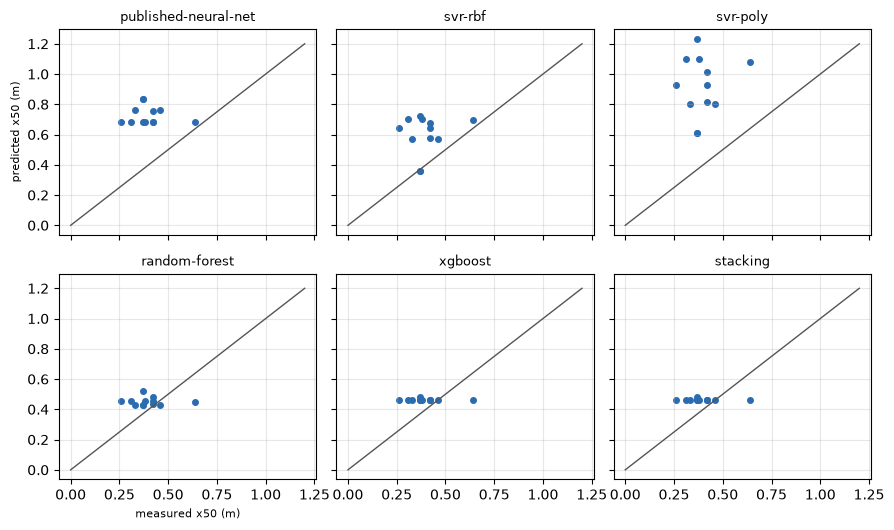

In [5]:
# Predicted against measured size on Enusa, one panel per learned arm
measured = np.array([b.x50_m for b in test_rows])
fig, axes = plt.subplots(2, 3, figsize=(9, 5.4), sharex=True, sharey=True)
for ax, name in zip(axes.flat, learned):
    predicted = np.array([p.x50_m for p in results[name]])
    ax.scatter(measured, predicted, s=16, color="#2b6cb0")
    ax.plot([0, 1.2], [0, 1.2], color="#555", lw=1)
    ax.set_title(name, fontsize=9)
    ax.grid(alpha=0.3)
axes[1, 0].set_xlabel("measured x50 (m)", fontsize=8)
axes[0, 0].set_ylabel("predicted x50 (m)", fontsize=8)
fig.tight_layout()
plt.show()

## Results

**The fit and the predict are the whole story.** Every learned arm reproduces the committed Enusa prediction to the six decimals the file stores. The committed artifact is a faithful record of what a held-out fit gives, not a separate calculation.

**On a campaign it has not seen, no learned arm is accurate.** The scores on Enusa range from poor to extremely poor: the neural network, the radial support vector regressor and the polynomial one fall far below zero, which means their predictions are worse than the mean of the measurements by a wide margin, and the tree-based arms land around -0.5, better than the null (about -1.4 on this campaign) but still below zero. A negative variance explained is not a bug; it says the prediction is further from the data than a constant is.

**Why the numbers are so extreme.** Enusa's measured sizes vary little (the same reason the classical arm scored badly inside one campaign), so a small absolute error divided by a small spread gives a large negative score. The RMSE and the bias columns are the fairer read for one campaign: they show errors of the order of a decimetre, and the sign of the bias says whether the arm over- or under-predicts.

**What this does not show.** One held-out campaign is one test of one arm. The next notebook repeats the exercise for every campaign and every arm of the ladder and pools the result, which is the only score the product leads with.

## Summary

- Learned arms are fitted on the rows of nine campaigns and predict the tenth; the committed artifact records exactly that.
- On Enusa the network and the support vector regressors score far below zero and the tree-based arms around -0.5; one campaign is a small test.
- Next: notebook 02 runs all fourteen arms through the ten folds and explains each refusal.

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the back-propagation network)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression, rbf)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (support vector polynomial, forest, boosting, stacking)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/